# TPE Fundamentos de la Ciencia de Datos 2026 - Grupo 34 

## 0-Paquetes,dataframe,links  

### Paquetes

In [178]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm


### Links usados
https://www.indec.gob.ar/ftp/cuadros/publicaciones/enfr_2018_resultados_definitivos.pdf 

https://www.indec.gob.ar/ftp/cuadros/menusuperior/enfr/manual_base_usuario_enfr2018.pdf

### Dataframe

In [179]:
raw_df = pd.read_csv("ENFR 2018 - Base usuario.txt", sep="|")
df=raw_df.copy()
raw_df.head()

,id,cod_provincia,region,tamanio_aglomerado,aglomerado,localidades_150,submuestra,bhcv01,bhcv02,bhcv03,...,glucemia_elevada,prevalencia_glucemia_elevada_combinada,findrisc,bimq06,bimq06_01,colesterol_elevado,prevalencia_colesterol_combinada,wf1p,wf2p,wf3p
0,1128639,2,1,1,1,1,1,3,2,1,...,NaN,NaN,2.0,NaN,NaN,NaN,NaN,2378,4464,0
1,1709939,2,1,1,1,1,0,1,4,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3588,0,0
2,6874130,2,1,1,1,1,0,3,2,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2740,0,0
3,10319375,2,1,1,1,1,1,3,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,493,0,0
4,11140857,2,1,1,1,1,0,3,3,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016,0,0


## 1-Análisis exploratorio inicial

### Presentación

El Instituto Nacional de Estadística y Censos (INDEC) conjuntamente con el Ministerio de Salud y Desarrollo Social (MSyDS) realizaron la 4º Encuesta Nacional de Factores de Riesgo (ENFR) en 2018, con el objetivo de proporcionar información válida, confiable y oportuna sobre factores de riesgo (como consumo de tabaco, alcohol, alimentación, actividad física, entre otros), procesos de atención en el sistema de salud y principales enfermedades no transmisibles (ENT) en la población (hipertensión, diabetes, obesidad y otras). Se trata de la cuarta encuesta de este tipo llevada a cabo en el país, las anteriores se desarrollando en 2005, 2009 y 2013.

### Objetivos de la Encuesta

1. Proporcionar información válida, confiable y oportuna sobre factores de riesgo, procesos de atención en el sistema de salud y prevalencias de las principales ENT (hipertensión, diabetes, obesidad y otras) en la población de 18 años y más, residente en viviendas particulares de áreas urbanas de 5.000 y más habitantes de la República Argentina.

2. Monitorear la evolución de los principales factores de riesgo de las ENT.

3. Evaluar el impacto de políticas de prevención y control realizadas a nivel nacional y provincial.

4. Proporcionar parámetros objetivos de los principales factores de riesgo y las ENT a partir de las mediciones físicas y bioquímicas.

### Variables

Las variables del dataset representan las respuestas al cuestionario, el cual esta conformado por dos bloques, el bloque hogar y el bloque individual 

#### Bloque Hogar (BH)

Destinado a relevar datos sobre condiciones habitacionales, así como características demográficas y educativas de todas las personas que conforman el hogar y datos laborales del jefe del hogar, cuya estructura de capítulos se detalla a continuación:

Detección de viviendas y hogares (DV)

Componentes del hogar (CH)

Caraterísticas de la vivienda (CV)

Carácterísticas del hogar (CH)

Ingresos del hogar (IH)

Situación laboral del jefe o jefa del hogar (SL)

#### Bloque Individual (BI)

Destinado a registrar datos laborales, así como información sobre los factores de riesgo de las ENT.

Este bloque se subdividió en tres partes, de acuerdo a los pasos para los que debían proveer información.

##### Paso 1

Capítulos correspondientes a la información por autorreporte. Su estructura y contenido es similar al utilizado en las tres ediciones anteriores de la ENFR:

- Situación laboral (SL)

- Salud general (SG)

- Actividad física (AF)

- Tabaco (TA)

- Hipertensión arterial (HA)

- Peso corporal (PC)

- Alimentación (AL)

- Colesterol (CO)

- Consumo de alcohol (CA)

- Diabetes (DM)

- Lesiones (LE)

- Prácticas preventivas (PP)

- Prevención de cáncer colorrectal (CC)

- Embarazo (EM)

Utiliza el factor de expansión wf1p.

##### Paso 2 (Mediciones Físicas/Antropométricas): 
Medición objetiva de presión arterial, peso, talla y perímetro de cintura sobre una submuestra nacional
. Utiliza el factor de expansión wf2p.


##### Paso 3 (Mediciones Bioquímicas): 
Análisis de glucemia capilar y colesterol total en una submuestra urbana (localidades de 150.000+ habitantes)
. Utiliza el factor de expansión wf3p.



### Tipos de variables presentadas

En la base se han utilizado dos tipos de variables.

Estos tipos de variables son:

- aquellas cuyo campo se identifica con el nombre de la pregunta del cuestionario;

- aquellas cuyo campo se identifica con un nombre especial, ya que fueron construidas a través de una secuencia de preguntas.

Los nombres del primer tipo de variables están formados por un mínimo de seis caracteres, incluyendo letras y números. Las primeras dos letras determinan el bloque (Hogar: BH individual: BI), las dos siguientes corresponden al capítulo en el cuestionario, cada capítulo tiene entre paréntesis las letras que lo identifican- y, por último, dos dígitos que se refieren al orden de la pregunta dentro del capítulo. En el caso de las subpreguntas, se registran los caracteres adicionales que componen el nombre de la pregunta en el cuestionario. En el caso de las variables de características sociodemográficas del jefe o de la jefa del hogar y del miembro seleccionado, estas se identifican con las iniciales del bloque Hogar y el capítulo en el que se relevaron ("Componentes del hogar" CH), diferenciándose las variables que se refieren al jefe del hogar tienen la letra jota (J) al final del nombre.

En el caso de las variables numéricas, el cero (0) será un valor válido cuando la consistencia de la información relevada lo permita. Por ejemplo: la variable BISG01 es la pregunta número 1 del capítulo "Salud general" (SG) del bloque individual (BI).

La denominación de las variables construidas hace referencia a su descripción. Ejemplo: NIVEL_INSTRUCCION.

### Otras consideraciones técnicas

Se advierte que los campos en blanco, en general, se corresponden con saltos en la secuencia de preguntas.

Los códigos 99, 999 y 9999, que en general son el valor máximo de cada escala, se corresponden con datos que el encuestado no sabía o no quería contestar.

El código cero (0) es un valor válido para las variables numéricas tales como la cantidad de porciones de frutas o verduras consumidas en una semana típica (BIAL05 y BIAL07).

## 2-Limpieza de la Base

Analizando los datos, y viendo la cantidad de columnas(287), nos parecio mas conveniente delegar la limpieza al momento del analisis, ya que no tiene sentido limpiar columnas que no vamos a utilizar. 

## 3-Planteo de Hipotesis


### Univariada
"La mayoria de los Argentinos adultos probaron el cigarrillo durante su adolescencia (13-18 años)"

### Bivariada

"Agregarle sal a la comida causa hipertension"

### Multivariada

"Hay una relacion lineal inversa entre ingresos del hogar, consumo de alcohol y consumo de tabaco"

## 4-Validacion de Hipotesis

Hipotesis: Existe una relación lineal entre el índice de masa corporal, la presión
sistólica, el perímetro de la cintura, la edad y los valores de glucemia
capilar registrada en ayunas.

In [ ]:
# Verificaciones iniciales
columns = {"imc_bima":"imc",
           "promedio_sistolica": "presion",
            "bima13":"perimetro_cintura",
            "bhch04":"edad", 
            "bimq05":"glucosa_registrada"
}
dataset_hip_5 = df[df["bidi01"]==2].copy()
dataset_hip_5 = dataset_hip_5[["imc_bima","promedio_sistolica","bima13","bhch04","bimq05"]]
dataset_hip_5 = dataset_hip_5.rename(columns=columns)
dataset_hip_5 = dataset_hip_5[(dataset_hip_5["glucosa_registrada"] <= 125) & (dataset_hip_5["glucosa_registrada"] >= 60)]
print(dataset_hip_5)

         imc  presion  perimetro_cintura  edad  glucosa_registrada
5      24.22      NaN               88.0    25                89.0
8      20.97    139.0               87.0    32                84.0
9      20.83      NaN               71.0    84                72.0
11     35.32    168.0              117.0    76                74.0
14     22.68    122.5               84.0    59                71.0
...      ...      ...                ...   ...                 ...
26864  31.55    148.5              110.0    74                54.0
26871    NaN    131.5               98.0    49                75.0
26876  26.89    124.0               87.0    29                80.0
26886  26.14    123.5               79.0    23                56.0
26894  43.76    158.5              128.0    69                64.0

[4400 rows x 5 columns]


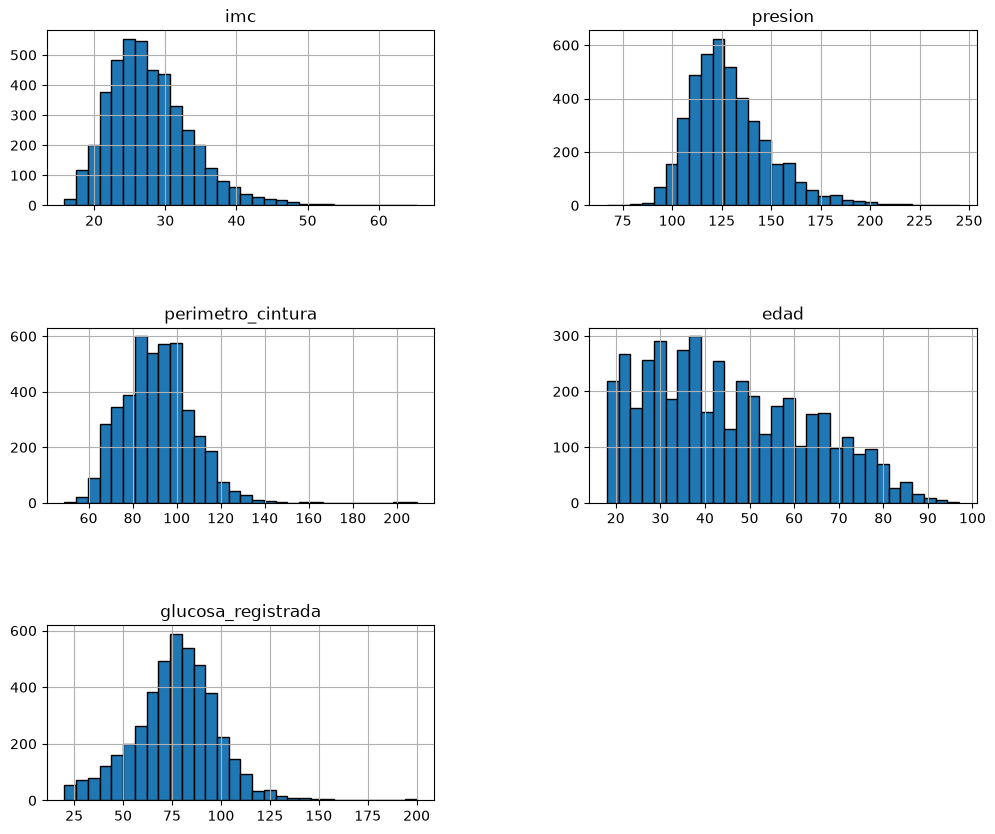

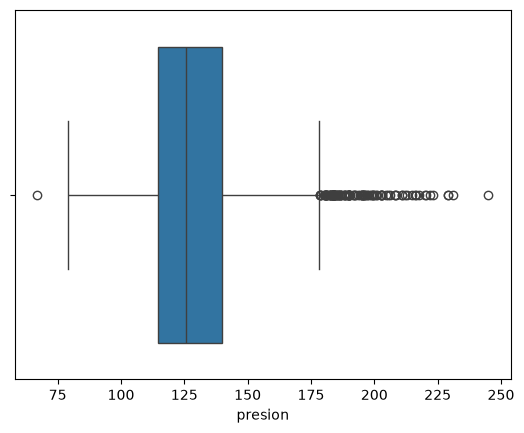

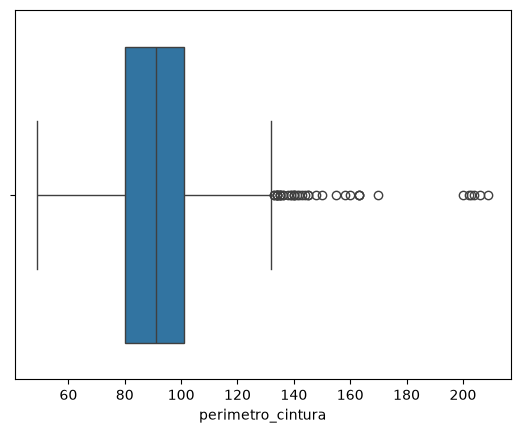

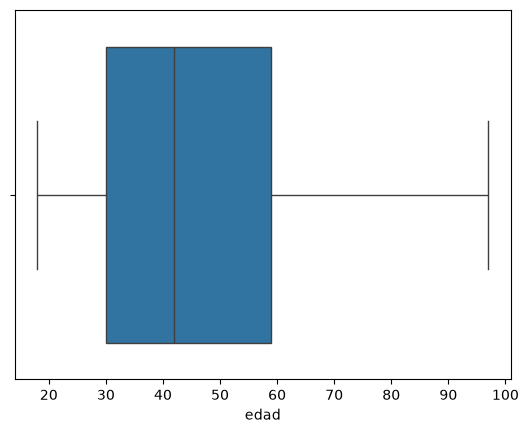

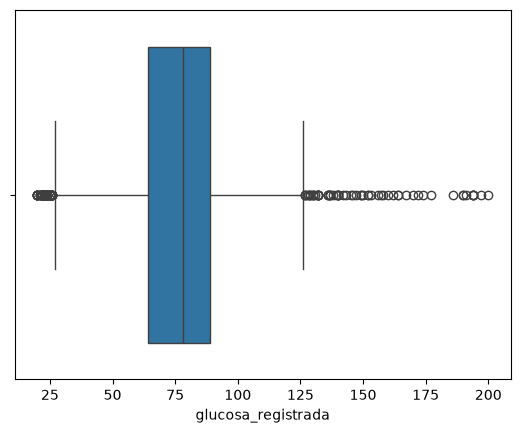

In [181]:
dataset_hip_5.hist(figsize=(12,10),bins=30, edgecolor="black")
plt.subplots_adjust(hspace=0.7, wspace=0.4)

columns = dataset_hip_5.columns.to_list()

for column in columns:
    # Create a box plot
    g = sns.boxplot(data = dataset_hip_5, x = column)
    g.set_label(f"Box plot of {column}")
    g.set_xlabel(f"{column}")
    plt.show()

Se observa que de los datos disponibles solos 5188 tienen valores válidos de nuestra variable objetivo, se considerarán de entre solo esos aquellos que además tengan todas las variables definidas.

Para validar la hipotesis, se intentará ajustar los datos a una regresión lineal múltiple

In [182]:
dataset_hip_5 = dataset_hip_5.dropna(axis=0, how="any")
dataset_hip_5 = dataset_hip_5.reset_index(drop=True)
print(dataset_hip_5.info())
print(dataset_hip_5.describe())

<class 'pandas.DataFrame'>
RangeIndex: 4277 entries, 0 to 4276
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   imc                 4277 non-null   float64
 1   presion             4277 non-null   float64
 2   perimetro_cintura   4277 non-null   float64
 3   edad                4277 non-null   int64  
 4   glucosa_registrada  4277 non-null   float64
dtypes: float64(4), int64(1)
memory usage: 167.2 KB
None
               imc      presion  perimetro_cintura         edad  \
count  4277.000000  4277.000000        4277.000000  4277.000000   
mean     27.830521   128.832359          91.129296    44.915829   
std       5.739230    20.445402          15.857258    17.764056   
min      15.820000    67.000000          49.000000    18.000000   
25%      23.730000   114.500000          80.000000    30.000000   
50%      27.040000   125.500000          91.000000    42.000000   
75%      30.960000   140.000000     

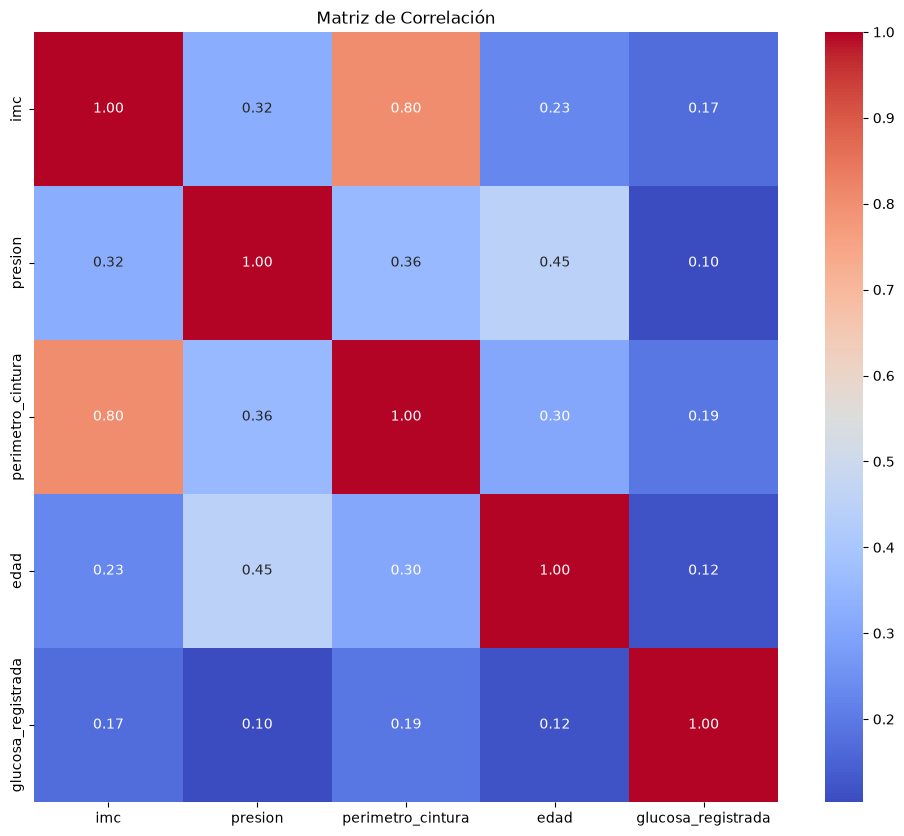

In [183]:
correlation_matrix = dataset_hip_5.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlación')
plt.show()

In [184]:
X = dataset_hip_5.drop("glucosa_registrada",axis=1)
X = X.drop("presion",axis=1)
y = dataset_hip_5["glucosa_registrada"].copy().to_frame()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
# Imprimir las medias y desviaciones estándar antes del escalado
print("Medias y desviaciones estándar antes del escalado:")
print(pd.DataFrame(X).describe().loc[['mean', 'std']])
y_scaled = scaler.fit_transform(y)
y_scaled_df = pd.DataFrame(y_scaled, columns=y.columns)

# Imprimir las medias y desviaciones estándar después del escalado
print("\nMedias y desviaciones estándar después del escalado:")
print(pd.DataFrame(X_scaled_df).describe().loc[['mean', 'std']])

Medias y desviaciones estándar antes del escalado:
            imc  perimetro_cintura       edad
mean  27.830521          91.129296  44.915829
std    5.739230          15.857258  17.764056

Medias y desviaciones estándar después del escalado:
               imc  perimetro_cintura          edad
mean -2.658098e-17      -3.721337e-16 -8.638817e-17
std   1.000117e+00       1.000117e+00  1.000117e+00


In [185]:
X_scaled_df_ = sm.add_constant(X_scaled_df)
model = sm.OLS(y, X_scaled_df_).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:     glucosa_registrada   R-squared:                       0.042
Model:                            OLS   Adj. R-squared:                  0.041
Method:                 Least Squares   F-statistic:                     62.27
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           2.12e-39
Time:                        01:39:10   Log-Likelihood:                -19179.
No. Observations:                4277   AIC:                         3.837e+04
Df Residuals:                    4273   BIC:                         3.839e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                76.5553      0.32

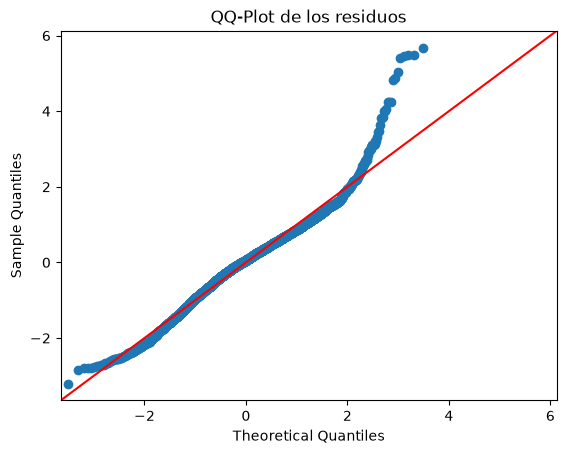

p = 0.0000
No se distribuyen normal (se rechazó la hipótesis nula)


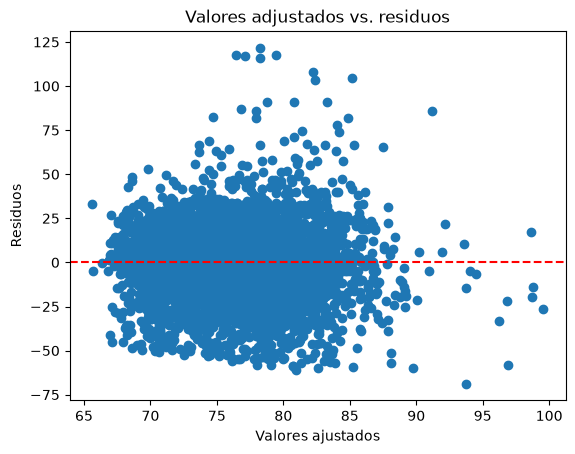

In [186]:
# QQ-Plot
zresid = (model.resid-model.resid.mean())/model.resid.std()
sm.qqplot(zresid, line='45')
plt.title("QQ-Plot de los residuos")
plt.show()

# aplicamos Shapiro-Wilk sobre los residuos
_, p = stats.shapiro(model.resid)
print("p = %.4f" % (p))
# comparamos con el alpha
alpha = 0.05
if p > alpha:
    print("Se distribuyen normal (falló en rechazarse la hipótesis nula)")
else:
    print('No se distribuyen normal (se rechazó la hipótesis nula)')

plt.scatter(model.fittedvalues, model.resid)
plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Valores adjustados vs. residuos")
plt.axhline(0, color='red', linestyle='--')
plt.show()

In [187]:
# Fit a GLM with a Gamma distribution and Log link
glm_model = sm.GLM(
    dataset_hip_5['glucosa_registrada'], 
    sm.add_constant(dataset_hip_5[['imc', 'presion', 'perimetro_cintura', 'edad']]),
    family=sm.families.Gamma(link=sm.families.links.Log())
).fit()

print(glm_model.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:     glucosa_registrada   No. Observations:                 4277
Model:                            GLM   Df Residuals:                     4272
Model Family:                   Gamma   Df Model:                            4
Link Function:                    Log   Scale:                        0.077594
Method:                          IRLS   Log-Likelihood:                -19337.
Date:                Tue, 03 Nov 2026   Deviance:                       386.87
Time:                        01:39:10   Pearson chi2:                     331.
No. Iterations:                     8   Pseudo R-squ. (CS):            0.04355
Covariance Type:            nonrobust                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 3.9858      0.03